<a href="https://colab.research.google.com/github/vir6903-prog/Movie-Reco/blob/main/notebooks/air_quality_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
import os

from sklearn.preprocessing import LabelEncoder

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
from google.colab import files

uploaded = files.upload()

Saving archive (3).zip to archive (3) (1).zip


In [5]:
zip_file = list(uploaded.keys())[0]

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall("air_quality_data")

print("ZIP file extracted successfully!")

ZIP file extracted successfully!


In [6]:
files_list = os.listdir("air_quality_data")

print("Files in dataset:")
for file in files_list:
    print(file)

Files in dataset:
visakhapatnam_combined.csv
hyderabad_combined.csv
jaipur_combined.csv
mumbai_combined.csv
gwalior_combined.csv
kolkata_combined.csv
bengaluru_combined.csv
lucknow_combined.csv
delhi_combined.csv
chennai_combined.csv


In [7]:
all_data = []

for file in files_list:
    file_path = os.path.join("air_quality_data", file)

    temp_df = pd.read_csv(file_path)

    all_data.append(temp_df)

print("Number of city datasets loaded:", len(all_data))

Number of city datasets loaded: 10


In [8]:
df = pd.concat(all_data, ignore_index=True)

print("Combined dataset shape:", df.shape)

Combined dataset shape: (18270, 9)


In [9]:
df.head()

,Timestamp,Location,PM2.5,PM10,NO2,NH3,SO2,CO,O3
0,01-01-2020,Visakhapatnam - GVM Corporation,64.72,101.79,26.59,11.42,8.10,1.14,70.51
1,02-01-2020,Visakhapatnam - GVM Corporation,50.87,91.55,30.49,11.40,8.83,1.09,59.92
2,03-01-2020,Visakhapatnam - GVM Corporation,52.59,90.53,23.28,11.74,7.55,1.08,61.80
3,04-01-2020,Visakhapatnam - GVM Corporation,21.82,48.86,21.84,10.36,9.36,0.95,44.17
4,05-01-2020,Visakhapatnam - GVM Corporation,16.00,43.07,18.27,10.24,9.04,0.84,52.64


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18270 entries, 0 to 18269
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Timestamp  18270 non-null  object 
 1   Location   18270 non-null  object 
 2   PM2.5      17866 non-null  float64
 3   PM10       17294 non-null  float64
 4   NO2        17836 non-null  float64
 5   NH3        17159 non-null  float64
 6   SO2        17788 non-null  float64
 7   CO         17891 non-null  float64
 8   O3         17800 non-null  float64
dtypes: float64(7), object(2)
memory usage: 1.3+ MB


In [11]:
print("Columns:")
print(df.columns.tolist())

Columns:
['Timestamp', 'Location', 'PM2.5', 'PM10', 'NO2', 'NH3', 'SO2', 'CO', 'O3']


In [12]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 18270
Number of Columns: 9


In [13]:
df.describe()

,PM2.5,PM10,NO2,NH3,SO2,CO,O3
count,17866.000000,17294.000000,17836.000000,17159.000000,17788.000000,17891.000000,17800.00000
mean,55.888837,123.289071,31.339990,25.515288,11.879519,0.917765,29.82539
std,52.249187,84.477314,20.931313,23.636385,9.216859,0.625908,19.65390
min,1.280000,1.970000,0.020000,0.040000,0.010000,0.000000,0.07000
25%,23.180000,62.272500,16.090000,11.440000,5.720000,0.490000,14.94000
50%,40.760000,102.125000,27.020000,17.920000,9.640000,0.760000,26.90000
75%,69.350000,160.480000,41.660000,30.425000,15.480000,1.170000,39.94000
max,794.000000,999.990000,384.410000,297.830000,161.200000,7.820000,185.19000


In [14]:
print("Number of unique locations:", df["Location"].nunique())

print("\nLocations:")
print(df["Location"].unique())

Number of unique locations: 10

Locations:
['Visakhapatnam - GVM Corporation' 'Hyderabad - Central University'
 'Jaipur - Police Commissionerate'
 'Mumbai - Chhatrapati Shivaji Intl. Airport (T2)' 'Gwalior - City Center'
 'Kolkata - Rabindra Bharati University' 'Bengaluru - Silk Board'
 'Lucknow - Lalbagh' 'Delhi - Punjabi Bagh' 'Chennai - Alandur Bus Depot']


In [15]:
missing = df.isnull().sum()

print("Missing values:")
print(missing)

Missing values:
Timestamp       0
Location        0
PM2.5         404
PM10          976
NO2           434
NH3          1111
SO2           482
CO            379
O3            470
dtype: int64


In [16]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_table = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage": missing_percentage.round(2)
})

missing_table

,Missing Values,Percentage
Timestamp,0,0.00
Location,0,0.00
PM2.5,404,2.21
PM10,976,5.34
NO2,434,2.38
NH3,1111,6.08
SO2,482,2.64
CO,379,2.07
O3,470,2.57


In [17]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [18]:
df = df.drop_duplicates().reset_index(drop=True)

print("Dataset shape after removing duplicates:", df.shape)
print("Duplicates remaining:", df.duplicated().sum())

Dataset shape after removing duplicates: (18270, 9)
Duplicates remaining: 0


In [19]:
df["Timestamp"] = pd.to_datetime(
    df["Timestamp"],
    format="%d-%m-%Y",
    errors="coerce"
)

print(df["Timestamp"].dtype)

datetime64[ns]


In [20]:
print("Invalid timestamps:", df["Timestamp"].isnull().sum())

Invalid timestamps: 0


In [21]:
df["Year"] = df["Timestamp"].dt.year
df["Month"] = df["Timestamp"].dt.month
df["Day"] = df["Timestamp"].dt.day
df["DayOfWeek"] = df["Timestamp"].dt.dayofweek

df.head()

,Timestamp,Location,PM2.5,PM10,NO2,NH3,SO2,CO,O3,Year,Month,Day,DayOfWeek
0,2020-01-01,Visakhapatnam - GVM Corporation,64.72,101.79,26.59,11.42,8.10,1.14,70.51,2020,1,1,2
1,2020-01-02,Visakhapatnam - GVM Corporation,50.87,91.55,30.49,11.40,8.83,1.09,59.92,2020,1,2,3
2,2020-01-03,Visakhapatnam - GVM Corporation,52.59,90.53,23.28,11.74,7.55,1.08,61.80,2020,1,3,4
3,2020-01-04,Visakhapatnam - GVM Corporation,21.82,48.86,21.84,10.36,9.36,0.95,44.17,2020,1,4,5
4,2020-01-05,Visakhapatnam - GVM Corporation,16.00,43.07,18.27,10.24,9.04,0.84,52.64,2020,1,5,6


In [22]:
def assign_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Summer"
    elif month in [6, 7, 8, 9]:
        return "Monsoon"
    else:
        return "Post-Monsoon"

df["Season"] = df["Month"].apply(assign_season)

df[["Timestamp", "Month", "Season"]].head(10)

,Timestamp,Month,Season
0,2020-01-01,1,Winter
1,2020-01-02,1,Winter
2,2020-01-03,1,Winter
3,2020-01-04,1,Winter
4,2020-01-05,1,Winter
5,2020-01-06,1,Winter
6,2020-01-07,1,Winter
7,2020-01-08,1,Winter
8,2020-01-09,1,Winter
9,2020-01-10,1,Winter


In [23]:
pollutant_columns = [
    "PM2.5",
    "PM10",
    "NO2",
    "NH3",
    "SO2",
    "CO",
    "O3"
]

print("Pollutant columns:")
print(pollutant_columns)

Pollutant columns:
['PM2.5', 'PM10', 'NO2', 'NH3', 'SO2', 'CO', 'O3']


In [24]:
for col in pollutant_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print(df[pollutant_columns].dtypes)

PM2.5    float64
PM10     float64
NO2      float64
NH3      float64
SO2      float64
CO       float64
O3       float64
dtype: object


In [25]:
df[pollutant_columns].isnull().sum()

,0
PM2.5,404
PM10,976
NO2,434
NH3,1111
SO2,482
CO,379
O3,470


In [26]:
for col in pollutant_columns:
    df[col] = df[col].fillna(df[col].median())

print("Missing pollutant values after imputation:")
print(df[pollutant_columns].isnull().sum())

Missing pollutant values after imputation:
PM2.5    0
PM10     0
NO2      0
NH3      0
SO2      0
CO       0
O3       0
dtype: int64


In [27]:
for col in pollutant_columns:
    print(col, "negative values:", (df[col] < 0).sum())

PM2.5 negative values: 0
PM10 negative values: 0
NO2 negative values: 0
NH3 negative values: 0
SO2 negative values: 0
CO negative values: 0
O3 negative values: 0


In [28]:
label_encoder = LabelEncoder()

df["Location_Encoded"] = label_encoder.fit_transform(df["Location"])

df[["Location", "Location_Encoded"]].drop_duplicates().head(20)

,Location,Location_Encoded
0,Visakhapatnam - GVM Corporation,9
1827,Hyderabad - Central University,4
3654,Jaipur - Police Commissionerate,5
5481,Mumbai - Chhatrapati Shivaji Intl. Airport (T2),8
7308,Gwalior - City Center,3
9135,Kolkata - Rabindra Bharati University,6
10962,Bengaluru - Silk Board,0
12789,Lucknow - Lalbagh,7
14616,Delhi - Punjabi Bagh,2
16443,Chennai - Alandur Bus Depot,1


In [29]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


In [30]:
print("Total duplicate rows:", df.duplicated().sum())

Total duplicate rows: 0


In [31]:
print("Final Dataset Shape:", df.shape)

df.head()

Final Dataset Shape: (18270, 15)


,Timestamp,Location,PM2.5,PM10,NO2,NH3,SO2,CO,O3,Year,Month,Day,DayOfWeek,Season,Location_Encoded
0,2020-01-01,Visakhapatnam - GVM Corporation,64.72,101.79,26.59,11.42,8.10,1.14,70.51,2020,1,1,2,Winter,9
1,2020-01-02,Visakhapatnam - GVM Corporation,50.87,91.55,30.49,11.40,8.83,1.09,59.92,2020,1,2,3,Winter,9
2,2020-01-03,Visakhapatnam - GVM Corporation,52.59,90.53,23.28,11.74,7.55,1.08,61.80,2020,1,3,4,Winter,9
3,2020-01-04,Visakhapatnam - GVM Corporation,21.82,48.86,21.84,10.36,9.36,0.95,44.17,2020,1,4,5,Winter,9
4,2020-01-05,Visakhapatnam - GVM Corporation,16.00,43.07,18.27,10.24,9.04,0.84,52.64,2020,1,5,6,Winter,9


In [32]:
X = df.drop(columns=["PM2.5"])
y = df["PM2.5"]

print("Target Variable:", "PM2.5")
print("Features:", X.shape[1])
print("Target Shape:", y.shape)

Target Variable: PM2.5
Features: 14
Target Shape: (18270,)


In [33]:
df.to_csv("preprocessed_air_quality.csv", index=False)

print("Preprocessed dataset saved successfully!")

Preprocessed dataset saved successfully!


In [34]:
from google.colab import files

files.download("preprocessed_air_quality.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("preprocessed_air_quality.csv")

print("Dataset Shape:", df.shape)

Dataset Shape: (18270, 15)


In [36]:
print("Columns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Columns:
['Timestamp', 'Location', 'PM2.5', 'PM10', 'NO2', 'NH3', 'SO2', 'CO', 'O3', 'Year', 'Month', 'Day', 'DayOfWeek', 'Season', 'Location_Encoded']

First 5 rows:


,Timestamp,Location,PM2.5,PM10,NO2,NH3,SO2,CO,O3,Year,Month,Day,DayOfWeek,Season,Location_Encoded
0,2020-01-01,Visakhapatnam - GVM Corporation,64.72,101.79,26.59,11.42,8.10,1.14,70.51,2020,1,1,2,Winter,9
1,2020-01-02,Visakhapatnam - GVM Corporation,50.87,91.55,30.49,11.40,8.83,1.09,59.92,2020,1,2,3,Winter,9
2,2020-01-03,Visakhapatnam - GVM Corporation,52.59,90.53,23.28,11.74,7.55,1.08,61.80,2020,1,3,4,Winter,9
3,2020-01-04,Visakhapatnam - GVM Corporation,21.82,48.86,21.84,10.36,9.36,0.95,44.17,2020,1,4,5,Winter,9
4,2020-01-05,Visakhapatnam - GVM Corporation,16.00,43.07,18.27,10.24,9.04,0.84,52.64,2020,1,5,6,Winter,9


In [37]:
print("Data Types:")
print(df.dtypes)

Data Types:
Timestamp            object
Location             object
PM2.5               float64
PM10                float64
NO2                 float64
NH3                 float64
SO2                 float64
CO                  float64
O3                  float64
Year                  int64
Month                 int64
Day                   int64
DayOfWeek             int64
Season               object
Location_Encoded      int64
dtype: object


In [38]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Missing Values:
Timestamp           0
Location            0
PM2.5               0
PM10                0
NO2                 0
NH3                 0
SO2                 0
CO                  0
O3                  0
Year                0
Month               0
Day                 0
DayOfWeek           0
Season              0
Location_Encoded    0
dtype: int64

Duplicate Rows: 0


In [39]:
pollutants = ['PM2.5', 'PM10', 'NO2', 'NH3', 'SO2', 'CO', 'O3']

stats = df[pollutants].describe().T

stats

,count,mean,std,min,25%,50%,75%,max
PM2.5,18270.0,55.554297,51.716114,1.28,23.5825,40.760,68.4800,794.00
PM10,18270.0,122.158467,82.327474,1.97,64.4900,102.125,156.2300,999.99
NO2,18270.0,31.237369,20.691657,0.02,16.3500,27.020,41.2350,384.41
NH3,18270.0,25.053418,22.978216,0.04,11.8900,17.920,29.6475,297.83
SO2,18270.0,11.820436,9.101540,0.01,5.7800,9.640,15.2900,161.20
CO,18270.0,0.914493,0.619790,0.00,0.5000,0.760,1.1600,7.82
O3,18270.0,29.750134,19.404966,0.07,15.2100,26.900,39.4800,185.19


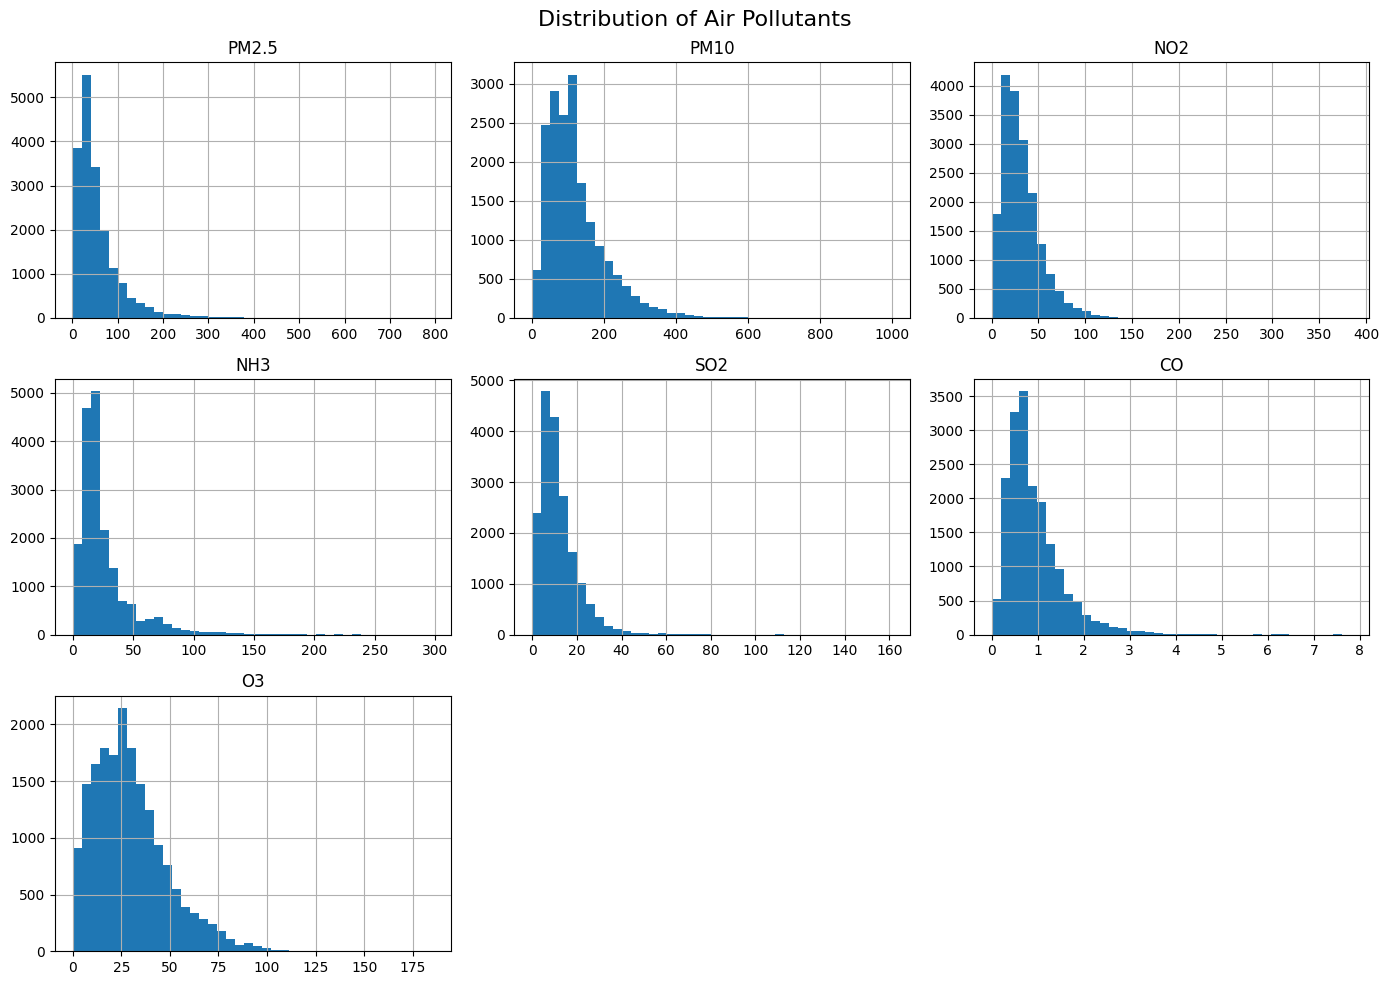

In [40]:
pollutants = ['PM2.5', 'PM10', 'NO2', 'NH3', 'SO2', 'CO', 'O3']

df[pollutants].hist(
    figsize=(14, 10),
    bins=40
)

plt.suptitle("Distribution of Air Pollutants", fontsize=16)
plt.tight_layout()
plt.show()

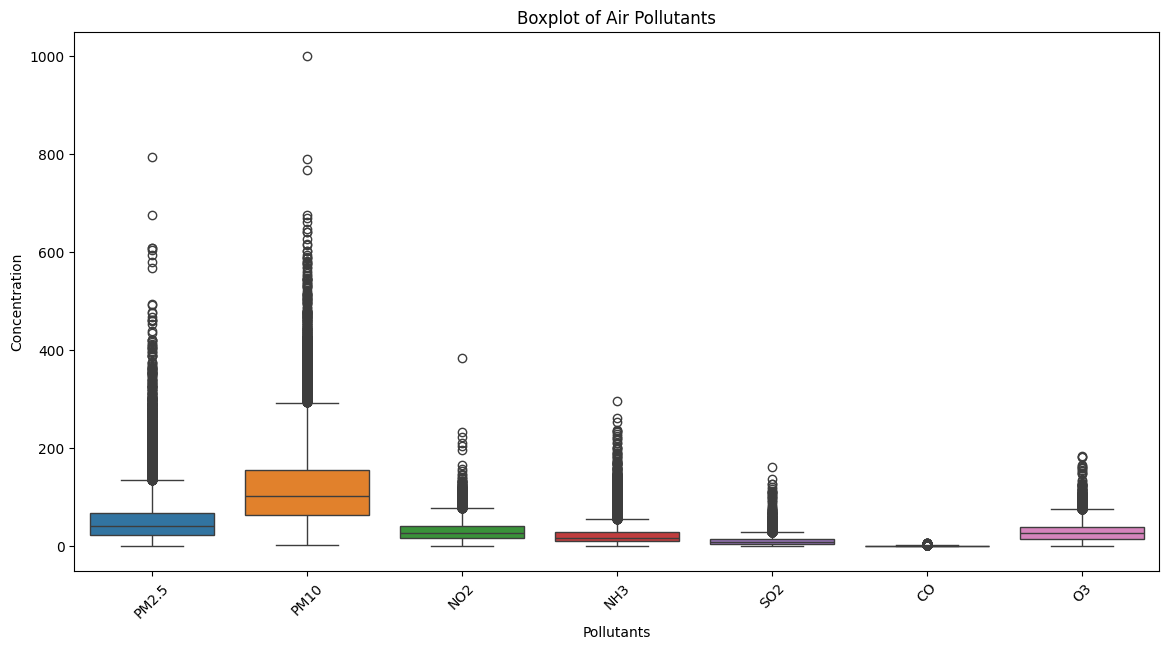

In [41]:
pollutants = ['PM2.5', 'PM10', 'NO2', 'NH3', 'SO2', 'CO', 'O3']

plt.figure(figsize=(14, 7))

sns.boxplot(data=df[pollutants])

plt.title("Boxplot of Air Pollutants")
plt.xlabel("Pollutants")
plt.ylabel("Concentration")
plt.xticks(rotation=45)

plt.show()

In [42]:
pollutants = ['PM2.5', 'PM10', 'NO2', 'NH3', 'SO2', 'CO', 'O3']

correlation = df[pollutants].corr()

print(correlation.round(2))

       PM2.5  PM10   NO2   NH3   SO2    CO    O3
PM2.5   1.00  0.87  0.48  0.29  0.18  0.47  0.11
PM10    0.87  1.00  0.51  0.32  0.19  0.47  0.12
NO2     0.48  0.51  1.00  0.32  0.03  0.38  0.04
NH3     0.29  0.32  0.32  1.00  0.02  0.37  0.09
SO2     0.18  0.19  0.03  0.02  1.00  0.10  0.19
CO      0.47  0.47  0.38  0.37  0.10  1.00  0.03
O3      0.11  0.12  0.04  0.09  0.19  0.03  1.00


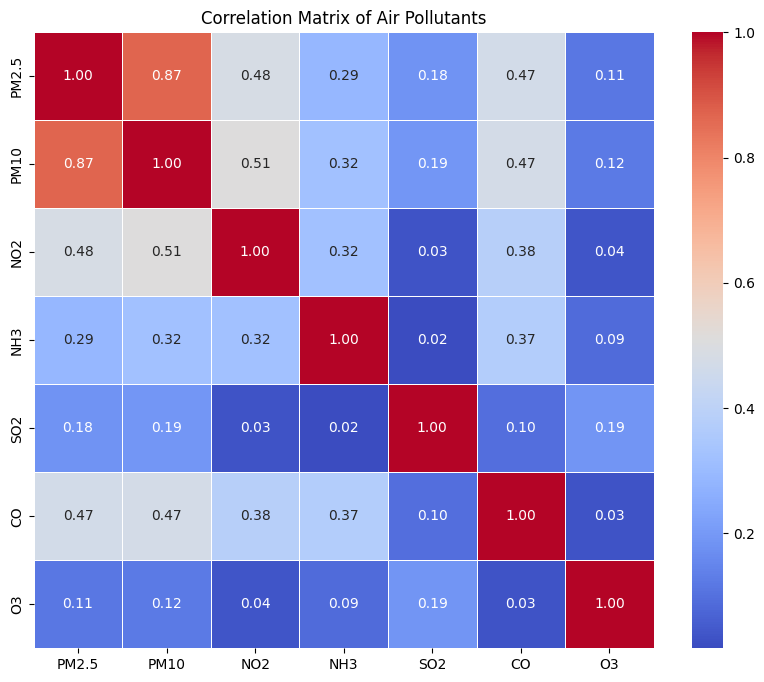

In [43]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Matrix of Air Pollutants")
plt.show()

In [44]:
df['Timestamp'] = pd.to_datetime(df['Timestamp'])

In [45]:
print(df['Timestamp'].dtype)
print(df['Timestamp'].min())
print(df['Timestamp'].max())

datetime64[ns]
2020-01-01 00:00:00
2024-12-31 00:00:00


In [46]:
yearly_avg = df.groupby('Year')[pollutants].mean()

yearly_avg

,PM2.5,PM10,NO2,NH3,SO2,CO,O3
Year,,,,,,,
2020,55.314896,116.319676,30.208642,21.206240,10.259888,0.778694,34.004358
2021,57.508962,122.431181,33.792586,25.326660,12.825011,0.956052,33.612682
2022,57.307444,131.825132,33.730786,25.996137,12.731123,0.933236,28.723030
2023,56.537132,123.899844,33.478030,26.608332,11.454274,1.022559,27.539252
2024,51.115869,116.348417,24.996719,26.137290,11.836115,0.882383,24.873052


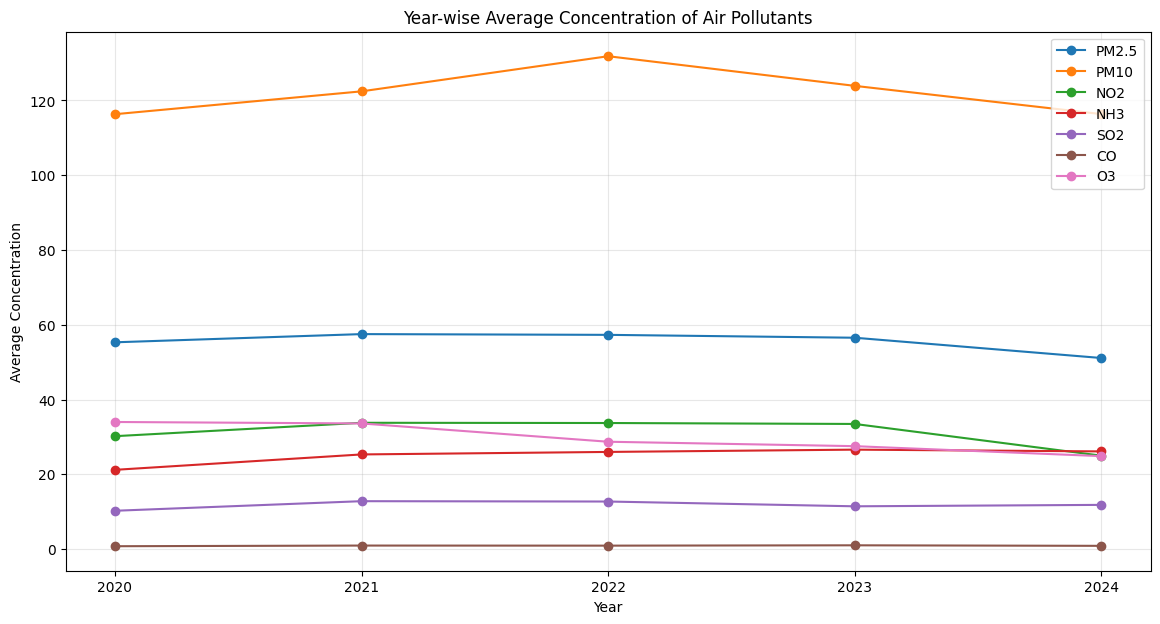

In [47]:
plt.figure(figsize=(14, 7))

for pollutant in pollutants:
    plt.plot(
        yearly_avg.index,
        yearly_avg[pollutant],
        marker='o',
        label=pollutant
    )

plt.title("Year-wise Average Concentration of Air Pollutants")
plt.xlabel("Year")
plt.ylabel("Average Concentration")
plt.xticks(yearly_avg.index)
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

In [48]:
seasonal_avg = df.groupby('Season')[pollutants].mean()

seasonal_avg

,PM2.5,PM10,NO2,NH3,SO2,CO,O3
Season,,,,,,,
Monsoon,28.929190,75.817467,22.826395,21.237184,10.470587,0.724293,27.044690
Post-Monsoon,74.283397,153.643213,37.193695,27.168403,11.544728,1.051662,30.687521
Summer,47.828287,117.267563,29.592333,23.908735,12.768059,0.845522,32.923967
Winter,86.711166,168.430542,40.243414,29.941440,12.863781,1.148810,29.538748


<Figure size 1400x700 with 0 Axes>

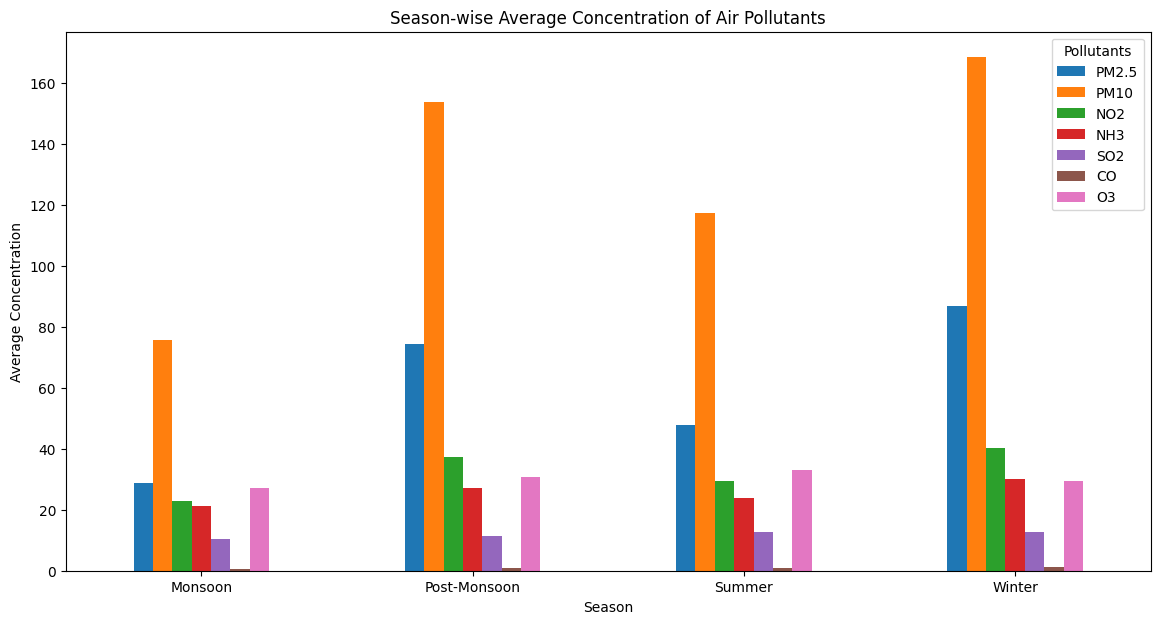

In [49]:
plt.figure(figsize=(14, 7))

seasonal_avg.plot(kind='bar', figsize=(14, 7))

plt.title("Season-wise Average Concentration of Air Pollutants")
plt.xlabel("Season")
plt.ylabel("Average Concentration")
plt.xticks(rotation=0)
plt.legend(title="Pollutants")

plt.show()

In [50]:
city_avg = df.groupby('Location')[pollutants].mean()
city_avg

,PM2.5,PM10,NO2,NH3,SO2,CO,O3
Location,,,,,,,
Bengaluru - Silk Board,32.329086,85.933251,24.558084,13.147794,5.851817,0.711111,27.680421
Chennai - Alandur Bus Depot,38.543339,78.279381,23.097531,18.957214,10.868719,1.080120,20.651719
Delhi - Punjabi Bagh,113.612003,211.262770,46.940126,23.219655,16.907449,1.216585,28.121199
Gwalior - City Center,59.488927,118.759220,24.946431,18.673284,21.007077,0.851954,46.158150
Hyderabad - Central University,29.230728,76.047712,33.965014,13.421987,4.944839,0.454921,22.423120
Jaipur - Police Commissionerate,60.562901,133.437326,44.423941,51.461730,13.288588,1.026705,39.815348
Kolkata - Rabindra Bharati University,58.736114,119.122868,20.776814,23.079945,14.634975,0.699699,38.486092
Lucknow - Lalbagh,82.886836,165.035512,33.651856,56.688779,7.425172,1.482600,32.530794
Mumbai - Chhatrapati Shivaji Intl. Airport (T2),34.735807,121.874860,25.062277,15.708112,11.822567,0.994116,19.804718


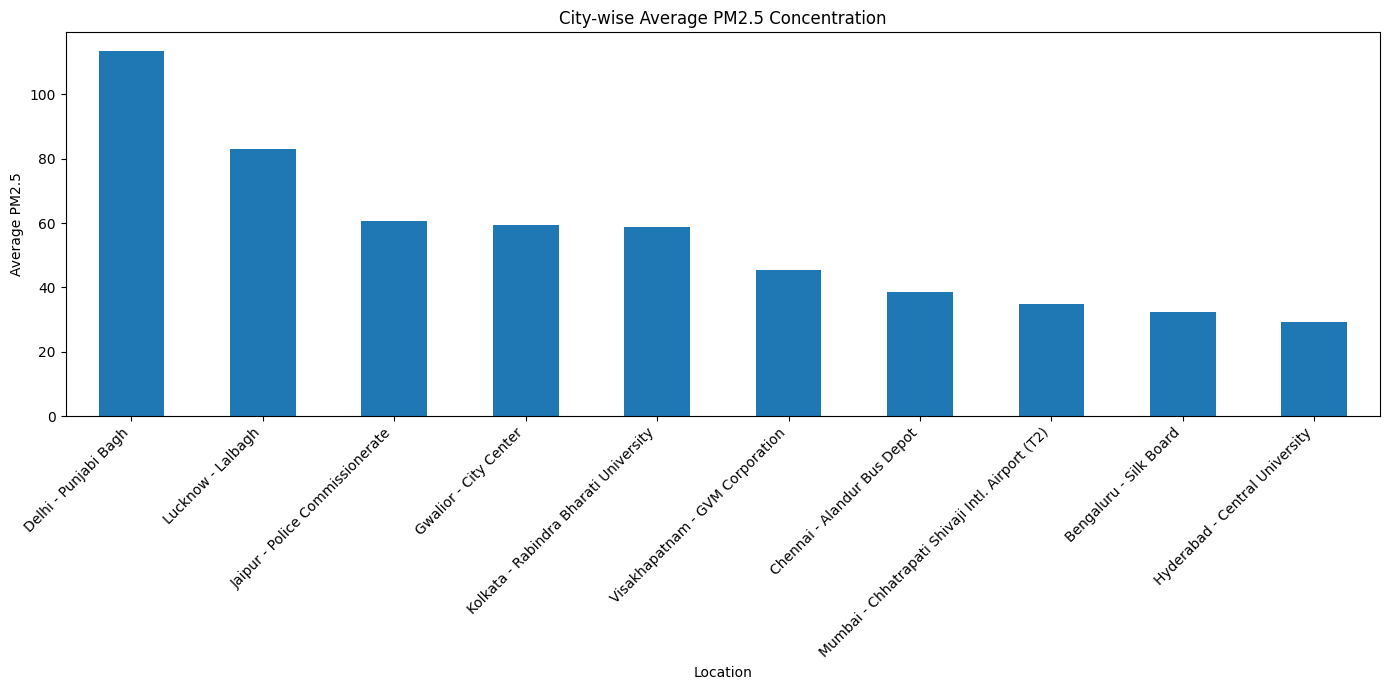

In [51]:
plt.figure(figsize=(14, 7))

city_avg['PM2.5'].sort_values(ascending=False).plot(kind='bar')

plt.title("City-wise Average PM2.5 Concentration")
plt.xlabel("Location")
plt.ylabel("Average PM2.5")
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

In [52]:
df.columns

Index(['Timestamp', 'Location', 'PM2.5', 'PM10', 'NO2', 'NH3', 'SO2', 'CO',
       'O3', 'Year', 'Month', 'Day', 'DayOfWeek', 'Season',
       'Location_Encoded'],
      dtype='object')

In [53]:
df['DayOfYear'] = df['Timestamp'].dt.dayofyear
df['WeekOfYear'] = df['Timestamp'].dt.isocalendar().week.astype(int)

df[['Timestamp', 'DayOfYear', 'WeekOfYear']].head()

,Timestamp,DayOfYear,WeekOfYear
0,2020-01-01,1,1
1,2020-01-02,2,1
2,2020-01-03,3,1
3,2020-01-04,4,1
4,2020-01-05,5,1


In [54]:
import numpy as np

df['Month_sin'] = np.sin(2 * np.pi * df['Month'] / 12)
df['Month_cos'] = np.cos(2 * np.pi * df['Month'] / 12)

df[['Month', 'Month_sin', 'Month_cos']].head()

,Month,Month_sin,Month_cos
0,1,0.5,0.866025
1,1,0.5,0.866025
2,1,0.5,0.866025
3,1,0.5,0.866025
4,1,0.5,0.866025


In [55]:
df['PM_Ratio'] = df['PM2.5'] / (df['PM10'] + 1e-6)

df[['PM2.5', 'PM10', 'PM_Ratio']].head()

,PM2.5,PM10,PM_Ratio
0,64.72,101.79,0.635819
1,50.87,91.55,0.555653
2,52.59,90.53,0.580912
3,21.82,48.86,0.446582
4,16.00,43.07,0.371488


In [56]:
df['Total_Pollutant_Load'] = (
    df['PM2.5'] +
    df['PM10'] +
    df['NO2'] +
    df['NH3'] +
    df['SO2'] +
    df['CO'] +
    df['O3']
)

df[['PM2.5', 'PM10', 'NO2', 'NH3', 'SO2', 'CO', 'O3',
    'Total_Pollutant_Load']].head()

,PM2.5,PM10,NO2,NH3,SO2,CO,O3,Total_Pollutant_Load
0,64.72,101.79,26.59,11.42,8.10,1.14,70.51,284.27
1,50.87,91.55,30.49,11.40,8.83,1.09,59.92,254.15
2,52.59,90.53,23.28,11.74,7.55,1.08,61.80,248.57
3,21.82,48.86,21.84,10.36,9.36,0.95,44.17,157.36
4,16.00,43.07,18.27,10.24,9.04,0.84,52.64,150.10


In [57]:
df = df.sort_values(['Location', 'Timestamp']).reset_index(drop=True)

df[['Location', 'Timestamp']].head(10)

,Location,Timestamp
0,Bengaluru - Silk Board,2020-01-01
1,Bengaluru - Silk Board,2020-01-02
2,Bengaluru - Silk Board,2020-01-03
3,Bengaluru - Silk Board,2020-01-04
4,Bengaluru - Silk Board,2020-01-05
5,Bengaluru - Silk Board,2020-01-06
6,Bengaluru - Silk Board,2020-01-07
7,Bengaluru - Silk Board,2020-01-08
8,Bengaluru - Silk Board,2020-01-09
9,Bengaluru - Silk Board,2020-01-10


In [58]:
lag_features = ['PM2.5', 'PM10', 'NO2', 'NH3', 'SO2', 'CO', 'O3']

for col in lag_features:
    df[f'{col}_Lag1'] = df.groupby('Location')[col].shift(1)

df[['Location', 'Timestamp', 'PM2.5', 'PM2.5_Lag1',
    'PM10', 'PM10_Lag1']].head(10)

,Location,Timestamp,PM2.5,PM2.5_Lag1,PM10,PM10_Lag1
0,Bengaluru - Silk Board,2020-01-01,40.76,NaN,102.125,NaN
1,Bengaluru - Silk Board,2020-01-02,43.67,40.76,134.000,102.125
2,Bengaluru - Silk Board,2020-01-03,30.58,43.67,74.420,134.000
3,Bengaluru - Silk Board,2020-01-04,66.35,30.58,155.680,74.420
4,Bengaluru - Silk Board,2020-01-05,48.00,66.35,99.130,155.680
5,Bengaluru - Silk Board,2020-01-06,23.75,48.00,63.340,99.130
6,Bengaluru - Silk Board,2020-01-07,24.67,23.75,72.000,63.340
7,Bengaluru - Silk Board,2020-01-08,34.18,24.67,79.060,72.000
8,Bengaluru - Silk Board,2020-01-09,41.61,34.18,98.000,79.060
9,Bengaluru - Silk Board,2020-01-10,38.95,41.61,97.700,98.000


In [59]:
df = df.dropna().reset_index(drop=True)

print("New Dataset Shape:", df.shape)
print("Missing Values:", df.isnull().sum().sum())

New Dataset Shape: (18260, 28)
Missing Values: 0


In [60]:
print(df[pollutants].describe().T[['min', 'max', 'mean']])

        min     max        mean
PM2.5  1.28  794.00   55.518066
PM10   1.97  999.99  122.136051
NO2    0.02  384.41   31.230829
NH3    0.04  297.83   25.054266
SO2    0.01  161.20   11.821012
CO     0.00    7.82    0.914296
O3     0.07  185.19   29.750197


In [61]:
print(df.dtypes)

Timestamp               datetime64[ns]
Location                        object
PM2.5                          float64
PM10                           float64
NO2                            float64
NH3                            float64
SO2                            float64
CO                             float64
O3                             float64
Year                             int64
Month                            int64
Day                              int64
DayOfWeek                        int64
Season                          object
Location_Encoded                 int64
DayOfYear                        int32
WeekOfYear                       int64
Month_sin                      float64
Month_cos                      float64
PM_Ratio                       float64
Total_Pollutant_Load           float64
PM2.5_Lag1                     float64
PM10_Lag1                      float64
NO2_Lag1                       float64
NH3_Lag1                       float64
SO2_Lag1                 

In [62]:
print(df.head())

   Timestamp                Location  PM2.5    PM10    NO2    NH3   SO2    CO  \
0 2020-01-02  Bengaluru - Silk Board  43.67  134.00  20.28  10.98  3.41  0.91   
1 2020-01-03  Bengaluru - Silk Board  30.58   74.42  15.17  12.10  3.27  0.96   
2 2020-01-04  Bengaluru - Silk Board  66.35  155.68  42.90  11.75  3.26  2.54   
3 2020-01-05  Bengaluru - Silk Board  48.00   99.13  18.56   9.79  2.95  1.14   
4 2020-01-06  Bengaluru - Silk Board  23.75   63.34  17.21   7.40  2.82  1.08   

      O3  Year  ...  Month_cos  PM_Ratio  Total_Pollutant_Load PM2.5_Lag1  \
0  21.82  2020  ...   0.866025  0.325896                235.07      40.76   
1  23.31  2020  ...   0.866025  0.410911                159.81      43.67   
2  29.70  2020  ...   0.866025  0.426195                312.18      30.58   
3  31.01  2020  ...   0.866025  0.484213                210.58      66.35   
4  25.82  2020  ...   0.866025  0.374961                141.42      48.00   

   PM10_Lag1  NO2_Lag1  NH3_Lag1  SO2_Lag1  CO_Lag

In [63]:
print(df['Location'].nunique())
print(df['Location'].unique())

10
['Bengaluru - Silk Board' 'Chennai - Alandur Bus Depot'
 'Delhi - Punjabi Bagh' 'Gwalior - City Center'
 'Hyderabad - Central University' 'Jaipur - Police Commissionerate'
 'Kolkata - Rabindra Bharati University' 'Lucknow - Lalbagh'
 'Mumbai - Chhatrapati Shivaji Intl. Airport (T2)'
 'Visakhapatnam - GVM Corporation']


In [64]:
# CPCB AQI breakpoint-based calculation

aqi_breakpoints = {
    'PM2.5': {
        'conc': [0, 30, 60, 90, 120, 250],
        'aqi':  [0, 50, 100, 200, 300, 400]
    },
    'PM10': {
        'conc': [0, 50, 100, 250, 350, 430],
        'aqi':  [0, 50, 100, 200, 300, 400]
    },
    'NO2': {
        'conc': [0, 40, 80, 180, 280, 400],
        'aqi':  [0, 50, 100, 200, 300, 400]
    },
    'NH3': {
        'conc': [0, 200, 400, 800, 1200, 1800],
        'aqi':  [0, 50, 100, 200, 300, 400]
    },
    'SO2': {
        'conc': [0, 40, 80, 380, 800, 1600],
        'aqi':  [0, 50, 100, 200, 300, 400]
    },
    'CO': {
        'conc': [0, 1, 2, 10, 17, 34],
        'aqi':  [0, 50, 100, 200, 300, 400]
    },
    'O3': {
        'conc': [0, 50, 100, 168, 208, 748],
        'aqi':  [0, 50, 100, 200, 300, 400]
    }
}

def calculate_subindex(concentration, pollutant):
    bp = aqi_breakpoints[pollutant]
    conc = bp['conc']
    aqi = bp['aqi']

    if concentration <= conc[0]:
        return 0

    # Above highest breakpoint
    if concentration > conc[-1]:
        return 500

    for i in range(len(conc) - 1):
        if conc[i] <= concentration <= conc[i + 1]:
            return (
                ((aqi[i + 1] - aqi[i]) /
                 (conc[i + 1] - conc[i]))
                * (concentration - conc[i])
                + aqi[i]
            )

    return np.nan

In [65]:
# Calculate pollutant-wise AQI sub-indices

aqi_pollutants = ['PM2.5', 'PM10', 'NO2', 'NH3', 'SO2', 'CO', 'O3']

for pollutant in aqi_pollutants:
    df[f'{pollutant}_AQI'] = df[pollutant].apply(
        lambda x: calculate_subindex(x, pollutant)
    )

# Overall AQI = maximum pollutant sub-index
df['AQI'] = df[[f'{p}_AQI' for p in aqi_pollutants]].max(axis=1)

print(df[['Timestamp', 'Location', 'AQI'] +
         [f'{p}_AQI' for p in aqi_pollutants]].head())

   Timestamp                Location         AQI   PM2.5_AQI    PM10_AQI  \
0 2020-01-02  Bengaluru - Silk Board  122.666667   72.783333  122.666667   
1 2020-01-03  Bengaluru - Silk Board   74.420000   50.966667   74.420000   
2 2020-01-04  Bengaluru - Silk Board  137.120000  121.166667  137.120000   
3 2020-01-05  Bengaluru - Silk Board   99.130000   80.000000   99.130000   
4 2020-01-06  Bengaluru - Silk Board   63.340000   39.583333   63.340000   

   NO2_AQI  NH3_AQI  SO2_AQI  CO_AQI  O3_AQI  
0  25.3500   2.7450   4.2625   45.50   21.82  
1  18.9625   3.0250   4.0875   48.00   23.31  
2  53.6250   2.9375   4.0750  106.75   29.70  
3  23.2000   2.4475   3.6875   57.00   31.01  
4  21.5125   1.8500   3.5250   54.00   25.82  


In [66]:
def aqi_category(aqi):
    if aqi <= 50:
        return "Good"
    elif aqi <= 100:
        return "Satisfactory"
    elif aqi <= 200:
        return "Moderate"
    elif aqi <= 300:
        return "Poor"
    elif aqi <= 400:
        return "Very Poor"
    else:
        return "Severe"


# AQI category
df['AQI_Category'] = df['AQI'].apply(aqi_category)

# Dominant pollutant
aqi_columns = [f'{p}_AQI' for p in aqi_pollutants]

df['Dominant_Pollutant'] = (
    df[aqi_columns]
    .idxmax(axis=1)
    .str.replace('_AQI', '', regex=False)
)

print(df[
    ['Timestamp', 'Location', 'AQI', 'AQI_Category', 'Dominant_Pollutant']
].head(10))

   Timestamp                Location         AQI  AQI_Category  \
0 2020-01-02  Bengaluru - Silk Board  122.666667      Moderate   
1 2020-01-03  Bengaluru - Silk Board   74.420000  Satisfactory   
2 2020-01-04  Bengaluru - Silk Board  137.120000      Moderate   
3 2020-01-05  Bengaluru - Silk Board   99.130000  Satisfactory   
4 2020-01-06  Bengaluru - Silk Board   63.340000  Satisfactory   
5 2020-01-07  Bengaluru - Silk Board   72.000000  Satisfactory   
6 2020-01-08  Bengaluru - Silk Board   79.060000  Satisfactory   
7 2020-01-09  Bengaluru - Silk Board   98.000000  Satisfactory   
8 2020-01-10  Bengaluru - Silk Board   97.700000  Satisfactory   
9 2020-01-11  Bengaluru - Silk Board   77.560000  Satisfactory   

  Dominant_Pollutant  
0               PM10  
1               PM10  
2               PM10  
3               PM10  
4               PM10  
5               PM10  
6               PM10  
7               PM10  
8               PM10  
9               PM10  


In [67]:
print("AQI Statistics:")
print(df['AQI'].describe())

print("\nAQI Category Distribution:")
print(df['AQI_Category'].value_counts())

print("\nDominant Pollutant Distribution:")
print(df['Dominant_Pollutant'].value_counts())

AQI Statistics:
count    18260.000000
mean       130.838873
std         90.988668
min         14.762500
25%         70.540000
50%        101.850000
75%        153.438333
max        500.000000
Name: AQI, dtype: float64

AQI Category Distribution:
AQI_Category
Moderate        7179
Satisfactory    6051
Good            1954
Poor            1461
Very Poor       1382
Severe           233
Name: count, dtype: int64

Dominant Pollutant Distribution:
Dominant_Pollutant
PM10     11241
PM2.5     4560
CO        1081
O3         657
NO2        640
SO2         80
NH3          1
Name: count, dtype: int64


In [68]:
# Create next-day AQI target for each city
df = df.sort_values(['Location', 'Timestamp']).reset_index(drop=True)

df['Target_AQI'] = (
    df.groupby('Location')['AQI']
      .shift(-1)
)

# Remove rows where next-day AQI is unavailable
df = df.dropna(subset=['Target_AQI']).reset_index(drop=True)

print("New Dataset Shape:", df.shape)
print("\nTarget AQI Statistics:")
print(df['Target_AQI'].describe())

print("\nSample:")
print(df[['Timestamp', 'Location', 'AQI', 'Target_AQI']].head(10))

New Dataset Shape: (18250, 39)

Target AQI Statistics:
count    18250.000000
mean       130.797660
std         90.938343
min         14.762500
25%         70.540000
50%        101.843333
75%        153.410000
max        500.000000
Name: Target_AQI, dtype: float64

Sample:
   Timestamp                Location         AQI  Target_AQI
0 2020-01-02  Bengaluru - Silk Board  122.666667       74.42
1 2020-01-03  Bengaluru - Silk Board   74.420000      137.12
2 2020-01-04  Bengaluru - Silk Board  137.120000       99.13
3 2020-01-05  Bengaluru - Silk Board   99.130000       63.34
4 2020-01-06  Bengaluru - Silk Board   63.340000       72.00
5 2020-01-07  Bengaluru - Silk Board   72.000000       79.06
6 2020-01-08  Bengaluru - Silk Board   79.060000       98.00
7 2020-01-09  Bengaluru - Silk Board   98.000000       97.70
8 2020-01-10  Bengaluru - Silk Board   97.700000       77.56
9 2020-01-11  Bengaluru - Silk Board   77.560000       75.93


In [69]:
# Chronological train-test split
train_df = df[df['Timestamp'].dt.year <= 2023].copy()
test_df = df[df['Timestamp'].dt.year == 2024].copy()

print("Training Set:", train_df.shape)
print("Testing Set :", test_df.shape)

print("\nTraining Period:")
print(train_df['Timestamp'].min(), "to", train_df['Timestamp'].max())

print("\nTesting Period:")
print(test_df['Timestamp'].min(), "to", test_df['Timestamp'].max())

Training Set: (14600, 39)
Testing Set : (3650, 39)

Training Period:
2020-01-02 00:00:00 to 2023-12-31 00:00:00

Testing Period:
2024-01-01 00:00:00 to 2024-12-30 00:00:00


In [70]:
# Columns that should NOT be used as input features
drop_columns = [
    'Timestamp',
    'Location',
    'AQI',
    'AQI_Category',
    'Dominant_Pollutant',
    'Target_AQI'
]

# Also remove individual pollutant AQI sub-index columns
aqi_subindex_columns = [f'{p}_AQI' for p in aqi_pollutants]

drop_columns.extend(aqi_subindex_columns)

# Create X and y
X_train = train_df.drop(columns=drop_columns)
y_train = train_df['Target_AQI']

X_test = test_df.drop(columns=drop_columns)
y_test = test_df['Target_AQI']

print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)

print("\nFeatures:")
print(X_train.columns.tolist())

print("\nTarget:", y_train.name)

X_train shape: (14600, 26)
X_test shape : (3650, 26)

Features:
['PM2.5', 'PM10', 'NO2', 'NH3', 'SO2', 'CO', 'O3', 'Year', 'Month', 'Day', 'DayOfWeek', 'Season', 'Location_Encoded', 'DayOfYear', 'WeekOfYear', 'Month_sin', 'Month_cos', 'PM_Ratio', 'Total_Pollutant_Load', 'PM2.5_Lag1', 'PM10_Lag1', 'NO2_Lag1', 'NH3_Lag1', 'SO2_Lag1', 'CO_Lag1', 'O3_Lag1']

Target: Target_AQI


In [71]:
# Encode Season as numerical values
season_mapping = {
    'Winter': 0,
    'Summer': 1,
    'Monsoon': 2,
    'Post-Monsoon': 3
}

X_train['Season'] = X_train['Season'].map(season_mapping)
X_test['Season'] = X_test['Season'].map(season_mapping)

print("X_train data types:")
print(X_train.dtypes)

print("\nMissing values in X_train:")
print(X_train.isnull().sum().sum())

print("\nMissing values in X_test:")
print(X_test.isnull().sum().sum())

X_train data types:
PM2.5                   float64
PM10                    float64
NO2                     float64
NH3                     float64
SO2                     float64
CO                      float64
O3                      float64
Year                      int64
Month                     int64
Day                       int64
DayOfWeek                 int64
Season                    int64
Location_Encoded          int64
DayOfYear                 int32
WeekOfYear                int64
Month_sin               float64
Month_cos               float64
PM_Ratio                float64
Total_Pollutant_Load    float64
PM2.5_Lag1              float64
PM10_Lag1               float64
NO2_Lag1                float64
NH3_Lag1                float64
SO2_Lag1                float64
CO_Lag1                 float64
O3_Lag1                 float64
dtype: object

Missing values in X_train:
0

Missing values in X_test:
0


In [72]:
# Final feature sanity check
print("Number of features:", X_train.shape[1])

print("\nFeatures containing AQI:")
print([col for col in X_train.columns if 'AQI' in col])

print("\nTrain/Test feature match:",
      list(X_train.columns) == list(X_test.columns))

print("\nTarget leakage check:")
print("Target_AQI in X_train:", 'Target_AQI' in X_train.columns)
print("Target_AQI in X_test :", 'Target_AQI' in X_test.columns)

Number of features: 26

Features containing AQI:
[]

Train/Test feature match: True

Target leakage check:
Target_AQI in X_train: False
Target_AQI in X_test : False


In [73]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=None,
    random_state=42,
    n_jobs=-1
)

# Train
rf_model.fit(X_train, y_train)

# Predict
rf_pred = rf_model.predict(X_test)

# Evaluate
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest Results")
print("---------------------")
print(f"MAE  : {rf_mae:.4f}")
print(f"RMSE : {rf_rmse:.4f}")
print(f"R²   : {rf_r2:.4f}")

Random Forest Results
---------------------
MAE  : 24.4459
RMSE : 38.5421
R²   : 0.7913


In [74]:
import xgboost as xgb

print("XGBoost version:", xgb.__version__)

XGBoost version: 3.4.1


In [75]:
from xgboost import XGBRegressor

# Create XGBoost model
xgb_model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    objective='reg:squarederror'
)

# Train
xgb_model.fit(X_train, y_train)

# Predict
xgb_pred = xgb_model.predict(X_test)

# Evaluate
xgb_mae = mean_absolute_error(y_test, xgb_pred)
xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_pred))
xgb_r2 = r2_score(y_test, xgb_pred)

print("XGBoost Results")
print("----------------")
print(f"MAE  : {xgb_mae:.4f}")
print(f"RMSE : {xgb_rmse:.4f}")
print(f"R²   : {xgb_r2:.4f}")

XGBoost Results
----------------
MAE  : 23.9969
RMSE : 37.8320
R²   : 0.7990


In [76]:
import lightgbm as lgb

print("LightGBM version:", lgb.__version__)

LightGBM version: 4.6.0


In [77]:
from lightgbm import LGBMRegressor

# Create LightGBM model
lgb_model = LGBMRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=-1,
    num_leaves=31,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

# Train
lgb_model.fit(X_train, y_train)

# Predict
lgb_pred = lgb_model.predict(X_test)

# Evaluate
lgb_mae = mean_absolute_error(y_test, lgb_pred)
lgb_rmse = np.sqrt(mean_squared_error(y_test, lgb_pred))
lgb_r2 = r2_score(y_test, lgb_pred)

print("LightGBM Results")
print("----------------")
print(f"MAE  : {lgb_mae:.4f}")
print(f"RMSE : {lgb_rmse:.4f}")
print(f"R²   : {lgb_r2:.4f}")

LightGBM Results
----------------
MAE  : 24.0978
RMSE : 38.0406
R²   : 0.7967


In [78]:
!pip install catboost -q

In [79]:
import catboost

print("CatBoost version:", catboost.__version__)

CatBoost version: 1.2.10


In [80]:
from catboost import CatBoostRegressor

# Create CatBoost model
cat_model = CatBoostRegressor(
    iterations=300,
    learning_rate=0.05,
    depth=6,
    loss_function='RMSE',
    random_seed=42,
    verbose=False
)

# Train
cat_model.fit(X_train, y_train)

# Predict
cat_pred = cat_model.predict(X_test)

# Evaluate
cat_mae = mean_absolute_error(y_test, cat_pred)
cat_rmse = np.sqrt(mean_squared_error(y_test, cat_pred))
cat_r2 = r2_score(y_test, cat_pred)

print("CatBoost Results")
print("----------------")
print(f"MAE  : {cat_mae:.4f}")
print(f"RMSE : {cat_rmse:.4f}")
print(f"R²   : {cat_r2:.4f}")

CatBoost Results
----------------
MAE  : 23.5503
RMSE : 37.4140
R²   : 0.8034


In [81]:
results = pd.DataFrame({
    'Model': ['Random Forest', 'XGBoost', 'LightGBM', 'CatBoost'],
    'MAE': [rf_mae, xgb_mae, lgb_mae, cat_mae],
    'RMSE': [rf_rmse, xgb_rmse, lgb_rmse, cat_rmse],
    'R2': [rf_r2, xgb_r2, lgb_r2, cat_r2]
})

print(results.to_string(index=False))

        Model       MAE      RMSE       R2
Random Forest 24.445877 38.542113 0.791343
      XGBoost 23.996946 37.832015 0.798961
     LightGBM 24.097807 38.040640 0.796738
     CatBoost 23.550315 37.414014 0.803379


In [82]:
comparison = pd.DataFrame({
    'Actual_AQI': y_test.values,
    'Predicted_AQI': cat_pred
})

print(comparison.head(10))

print("\nPrediction Statistics:")
print(comparison.describe())

   Actual_AQI  Predicted_AQI
0   96.740000     103.206704
1   96.150000     106.752105
2  107.606667     109.152263
3   72.300000     110.426722
4   67.880000      78.252526
5   60.070000      71.640966
6   40.230000      66.327925
7  500.000000      62.495914
8  500.000000     129.505856
9   92.830000     233.981983

Prediction Statistics:
        Actual_AQI  Predicted_AQI
count  3650.000000    3650.000000
mean    122.161747     124.174684
std      84.387624      75.584061
min      16.562500      35.369033
25%      68.500000      73.405214
50%     101.710000     104.897296
75%     138.578333     143.522742
max     500.000000     483.463002


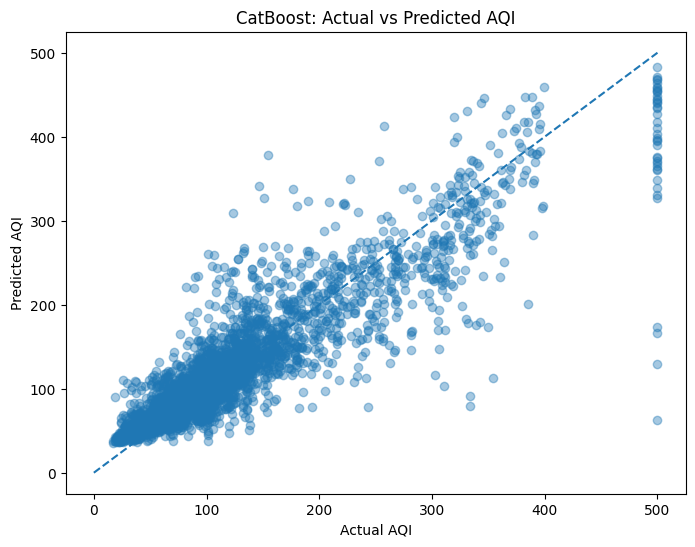

In [83]:
plt.figure(figsize=(8, 6))

plt.scatter(
    comparison['Actual_AQI'],
    comparison['Predicted_AQI'],
    alpha=0.4
)

# Perfect prediction line
max_val = max(
    comparison['Actual_AQI'].max(),
    comparison['Predicted_AQI'].max()
)

plt.plot(
    [0, max_val],
    [0, max_val],
    linestyle='--'
)

plt.xlabel('Actual AQI')
plt.ylabel('Predicted AQI')
plt.title('CatBoost: Actual vs Predicted AQI')

plt.show()

In [84]:
import shap

print("SHAP version:", shap.__version__)

SHAP version: 0.54.1


In [85]:
# Create SHAP explainer for the trained CatBoost model
explainer = shap.TreeExplainer(cat_model)

print("SHAP Explainer created successfully!")

SHAP Explainer created successfully!


In [86]:
# Use a representative sample of the test data
X_shap = X_test.sample(
    n=min(1000, len(X_test)),
    random_state=42
)

# Calculate SHAP values
shap_values = explainer.shap_values(X_shap)

print("SHAP values shape:", shap_values.shape)
print("SHAP analysis samples:", X_shap.shape[0])
print("Number of features:", X_shap.shape[1])

SHAP values shape: (1000, 26)
SHAP analysis samples: 1000
Number of features: 26


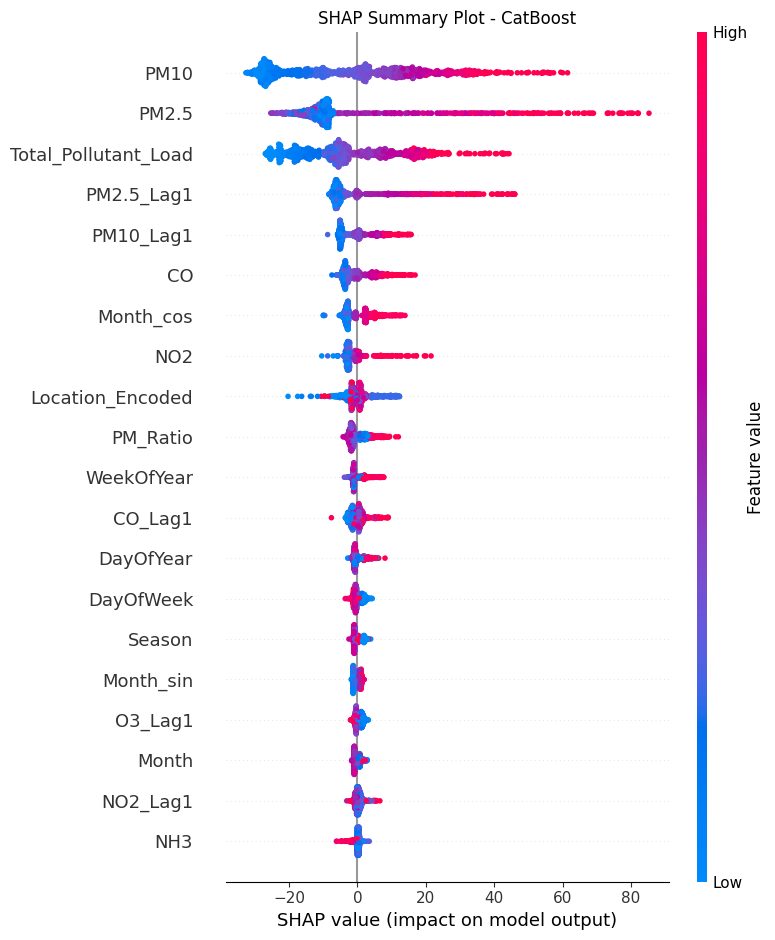

In [87]:
# SHAP Summary Plot
plt.figure(figsize=(10, 8))

shap.summary_plot(
    shap_values,
    X_shap,
    show=False
)

plt.title("SHAP Summary Plot - CatBoost")
plt.tight_layout()
plt.show()

In [88]:
# Calculate mean absolute SHAP importance
shap_importance = pd.DataFrame({
    'Feature': X_shap.columns,
    'Mean_Abs_SHAP': np.abs(shap_values).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    'Mean_Abs_SHAP',
    ascending=False
).reset_index(drop=True)

print(shap_importance.to_string(index=False))

             Feature  Mean_Abs_SHAP
                PM10      17.839335
               PM2.5      16.018650
Total_Pollutant_Load      12.579033
          PM2.5_Lag1       7.950957
           PM10_Lag1       4.202332
                  CO       3.636446
           Month_cos       3.567338
                 NO2       2.478199
    Location_Encoded       2.443339
            PM_Ratio       2.256066
          WeekOfYear       1.518368
             CO_Lag1       1.389798
           DayOfYear       1.220811
           DayOfWeek       1.078937
              Season       1.051741
           Month_sin       0.931562
             O3_Lag1       0.887228
               Month       0.735013
            NO2_Lag1       0.648286
                 NH3       0.518350
                Year       0.508739
                  O3       0.494997
            NH3_Lag1       0.385043
                 SO2       0.380020
            SO2_Lag1       0.333815
                 Day       0.157861


In [89]:
# Pollutant-only SHAP contribution
pollutants = [
    'PM2.5',
    'PM10',
    'NO2',
    'NH3',
    'SO2',
    'CO',
    'O3'
]

pollutant_shap = shap_importance[
    shap_importance['Feature'].isin(pollutants)
].copy()

# Calculate relative contribution percentage
total_pollutant_shap = pollutant_shap['Mean_Abs_SHAP'].sum()

pollutant_shap['Contribution_%'] = (
    pollutant_shap['Mean_Abs_SHAP'] /
    total_pollutant_shap * 100
)

pollutant_shap = pollutant_shap.sort_values(
    'Mean_Abs_SHAP',
    ascending=False
).reset_index(drop=True)

print(pollutant_shap.to_string(index=False))

Feature  Mean_Abs_SHAP  Contribution_%
   PM10      17.839335       43.125602
  PM2.5      16.018650       38.724196
     CO       3.636446        8.790906
    NO2       2.478199        5.990908
    NH3       0.518350        1.253083
     O3       0.494997        1.196627
    SO2       0.380020        0.918677


In [90]:
# Select 100 test samples from each city
city_indices = (
    test_df.groupby('Location', group_keys=False)
           .apply(lambda x: x.sample(n=100, random_state=42))
           .index
)

# Keep only the model features
X_city_shap = X_test.loc[city_indices]

# Get corresponding city names
city_labels = test_df.loc[city_indices, 'Location']

print("Total SHAP samples:", len(X_city_shap))
print("\nSamples per city:")
print(city_labels.value_counts())

Total SHAP samples: 1000

Samples per city:
Location
Bengaluru - Silk Board                             100
Chennai - Alandur Bus Depot                        100
Delhi - Punjabi Bagh                               100
Gwalior - City Center                              100
Hyderabad - Central University                     100
Jaipur - Police Commissionerate                    100
Kolkata - Rabindra Bharati University              100
Lucknow - Lalbagh                                  100
Mumbai - Chhatrapati Shivaji Intl. Airport (T2)    100
Visakhapatnam - GVM Corporation                    100
Name: count, dtype: int64


In [91]:
# Calculate SHAP values for the balanced city sample
city_shap_values = explainer.shap_values(X_city_shap)

print("City-wise SHAP shape:", city_shap_values.shape)
print("Samples:", X_city_shap.shape[0])
print("Features:", X_city_shap.shape[1])

City-wise SHAP shape: (1000, 26)
Samples: 1000
Features: 26


In [92]:
# Create SHAP DataFrame
city_shap_df = pd.DataFrame(
    city_shap_values,
    columns=X_city_shap.columns,
    index=X_city_shap.index
)

city_shap_df['Location'] = city_labels.values

# Pollutant features
pollutants = [
    'PM2.5',
    'PM10',
    'NO2',
    'NH3',
    'SO2',
    'CO',
    'O3'
]

# Mean absolute SHAP by city
city_pollutant_shap = (
    city_shap_df
    .groupby('Location')[pollutants]
    .apply(lambda x: np.abs(x).mean())
)

print(city_pollutant_shap)

                                                     PM2.5       PM10  \
Location                                                                
Bengaluru - Silk Board                           12.205716  12.680339   
Chennai - Alandur Bus Depot                      14.707894  20.344768   
Delhi - Punjabi Bagh                             35.076004  28.646987   
Gwalior - City Center                            16.590757  15.585497   
Hyderabad - Central University                   11.451551  17.982742   
Jaipur - Police Commissionerate                  15.892145  15.310919   
Kolkata - Rabindra Bharati University            14.479956  17.946543   
Lucknow - Lalbagh                                24.051850  23.413196   
Mumbai - Chhatrapati Shivaji Intl. Airport (T2)  12.794660  13.765393   
Visakhapatnam - GVM Corporation                  13.613278  11.579074   

                                                      NO2       NH3       SO2  \
Location                                  

In [93]:
# City-wise pollutant SHAP percentage contribution

city_pollutant_shap_pct = (
    city_pollutant_shap
    .div(city_pollutant_shap.sum(axis=1), axis=0)
    * 100
)

print(city_pollutant_shap_pct.round(2))

                                                 PM2.5   PM10   NO2   NH3  \
Location                                                                    
Bengaluru - Silk Board                           39.02  40.54  7.81  0.56   
Chennai - Alandur Bus Depot                      32.56  45.03  6.25  1.11   
Delhi - Punjabi Bagh                             46.68  38.13  5.96  1.09   
Gwalior - City Center                            42.66  40.07  5.33  0.93   
Hyderabad - Central University                   31.18  48.96  7.35  0.95   
Jaipur - Police Commissionerate                  42.49  40.93  5.57  2.60   
Kolkata - Rabindra Bharati University            37.52  46.51  6.31  0.95   
Lucknow - Lalbagh                                42.65  41.52  3.56  2.00   
Mumbai - Chhatrapati Shivaji Intl. Airport (T2)  37.84  40.71  6.59  1.06   
Visakhapatnam - GVM Corporation                  45.00  38.27  3.15  1.09   

                                                  SO2     CO    O3  
Locati

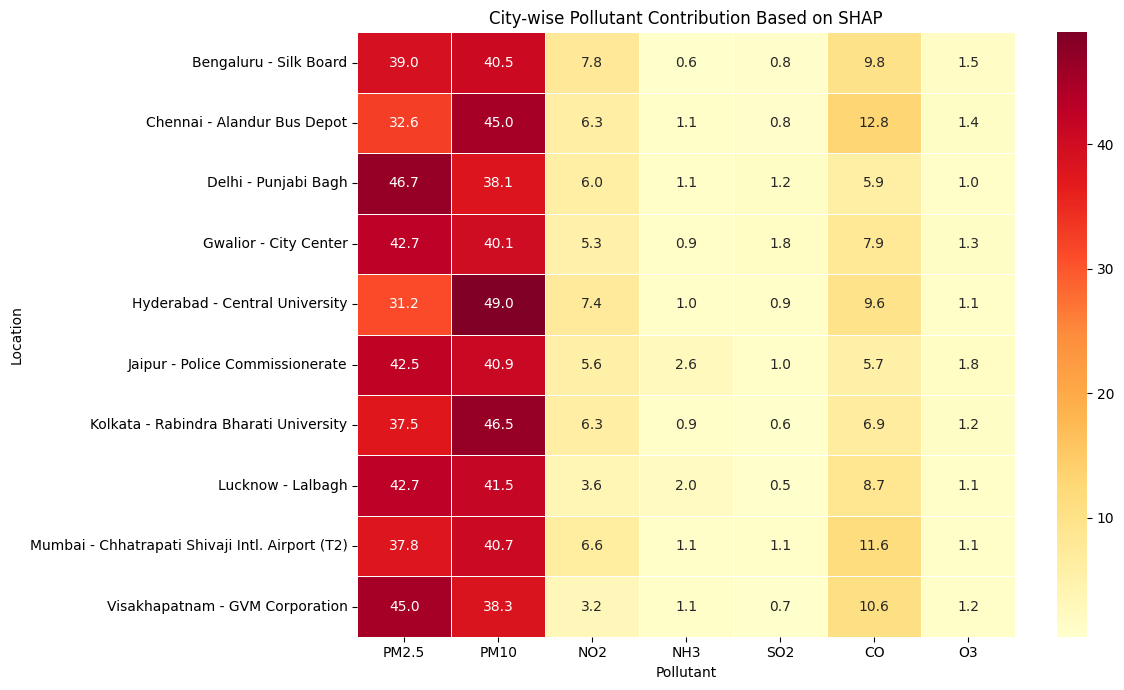

In [94]:
plt.figure(figsize=(12, 7))

sns.heatmap(
    city_pollutant_shap_pct,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.5
)

plt.title("City-wise Pollutant Contribution Based on SHAP")
plt.xlabel("Pollutant")
plt.ylabel("Location")
plt.tight_layout()
plt.show()

In [95]:
# Identify dominant pollutant for each city based on relative SHAP contribution

dominant_pollutant = city_pollutant_shap_pct.idxmax(axis=1)
dominant_contribution = city_pollutant_shap_pct.max(axis=1)

industrial_recommendations = pd.DataFrame({
    'Dominant_Pollutant': dominant_pollutant,
    'SHAP_Contribution_%': dominant_contribution.round(2)
})

print(industrial_recommendations)

                                                Dominant_Pollutant  \
Location                                                             
Bengaluru - Silk Board                                        PM10   
Chennai - Alandur Bus Depot                                   PM10   
Delhi - Punjabi Bagh                                         PM2.5   
Gwalior - City Center                                        PM2.5   
Hyderabad - Central University                                PM10   
Jaipur - Police Commissionerate                              PM2.5   
Kolkata - Rabindra Bharati University                         PM10   
Lucknow - Lalbagh                                            PM2.5   
Mumbai - Chhatrapati Shivaji Intl. Airport (T2)               PM10   
Visakhapatnam - GVM Corporation                              PM2.5   

                                                 SHAP_Contribution_%  
Location                                                              
Bengaluru - Silk 

In [96]:
# Industrial recommendations based on dominant SHAP pollutant

recommendation_map = {
    'PM2.5': (
        'Fine particulate emission control, '
        'combustion optimization, filtration and continuous emission monitoring'
    ),
    'PM10': (
        'Dust suppression, particulate filtration, '
        'bag filters/cyclones and continuous emission monitoring'
    ),
    'NO2': (
        'NOx emission monitoring, combustion optimization '
        'and appropriate NOx control systems'
    ),
    'NH3': (
        'Ammonia emission monitoring, process optimization '
        'and leakage/control measures'
    ),
    'SO2': (
        'SO2 monitoring, low-sulfur fuel/process control '
        'and flue-gas desulfurization where applicable'
    ),
    'CO': (
        'Combustion-efficiency monitoring, '
        'fuel optimization and CO emission control'
    ),
    'O3': (
        'Monitoring of ozone precursors and '
        'VOC/NOx emission management'
    )
}

industrial_recommendations['Recommended_Control_Focus'] = (
    industrial_recommendations['Dominant_Pollutant']
    .map(recommendation_map)
)

print(industrial_recommendations.to_string())

                                                Dominant_Pollutant  SHAP_Contribution_%                                                                                  Recommended_Control_Focus
Location                                                                                                                                                                                          
Bengaluru - Silk Board                                        PM10                40.54          Dust suppression, particulate filtration, bag filters/cyclones and continuous emission monitoring
Chennai - Alandur Bus Depot                                   PM10                45.03          Dust suppression, particulate filtration, bag filters/cyclones and continuous emission monitoring
Delhi - Punjabi Bagh                                         PM2.5                46.68  Fine particulate emission control, combustion optimization, filtration and continuous emission monitoring
Gwalior - City Center    